This is the Jupyter Notebook Version of the Haystack + RAG Implemented PDF Summarizer.   
Split the Notebook into scripts at the Markdown Headings. Imports will have to be separated as needed.  
Remove pipeline.show() 

### Imports


In [1]:
#Import Libraries

import os
import haystack
import streamlit as st
from openai import OpenAI
from pypdf import PdfReader
from dotenv import load_dotenv
import warnings
warnings.filterwarnings('ignore')




In [ ]:
#Haystack Imports


from haystack import Pipeline
from haystack.components.embedders import OpenAIDocumentEmbedder
from haystack.components.embedders import OpenAITextEmbedder
from haystack.document_stores.in_memory import InMemoryDocumentStore
from haystack.components.converters.pypdf import PyPDFToDocument
from haystack.components.preprocessors.document_splitter import DocumentSplitter
from haystack.components.preprocessors import DocumentCleaner
from haystack.components.writers import DocumentWriter
from haystack.components.retrievers.in_memory import InMemoryEmbeddingRetriever
from haystack.document_stores.in_memory import InMemoryDocumentStore

from haystack.utils import Secret


from haystack_integrations.components.embedders.mistral.document_embedder import (
    MistralDocumentEmbedder,
)
from haystack_integrations.components.embedders.mistral.text_embedder import (
    MistralTextEmbedder,
)




### Haystack Implementation

In [ ]:
#Haystack Components


#Convert PDF File to Document
converter = PyPDFToDocument()

#Cleaning
cleaner = DocumentCleaner(remove_empty_lines=True,
        remove_extra_whitespaces=True,
        remove_repeated_substrings=False)


#Chunking
splitter = DocumentSplitter(split_length = 800, split_overlap = 80)



#Embedding Model
embedder = MistralDocumentEmbedder(
    api_key=Secret.from_env_var("MISTRAL_EMBED_API_KEY"),
    model="mistral-embed",
)


#Document Store
doc_store = InMemoryDocumentStore()

#Write Embeddings into the Doc Store
writer = DocumentWriter(document_store = doc_store)




In [4]:
#Haystack Pipeline
#pipeline.py

#Building the Pipeline
pipeline = Pipeline()



#Assemble
pipeline.add_component("converter", converter)
pipeline.add_component("cleaner", cleaner)
pipeline.add_component("splitter", splitter)
pipeline.add_component("embedder", embedder)
pipeline.add_component("writer", writer)


#Connecting the Pipeline

pipeline.connect("converter", "cleaner")
pipeline.connect("cleaner", "splitter")
pipeline.connect("splitter", "embedder")
pipeline.connect("embedder", "writer")



🚅 Components
  - converter: PyPDFToDocument
  - cleaner: DocumentCleaner
  - splitter: DocumentSplitter
  - embedder: SentenceTransformersDocumentEmbedder
  - writer: DocumentWriter
🛤️ Connections
  - converter.documents -> cleaner.documents (list[Document])
  - cleaner.documents -> splitter.documents (list[Document])
  - splitter.documents -> embedder.documents (list[Document])
  - embedder.documents -> writer.documents (list[Document])

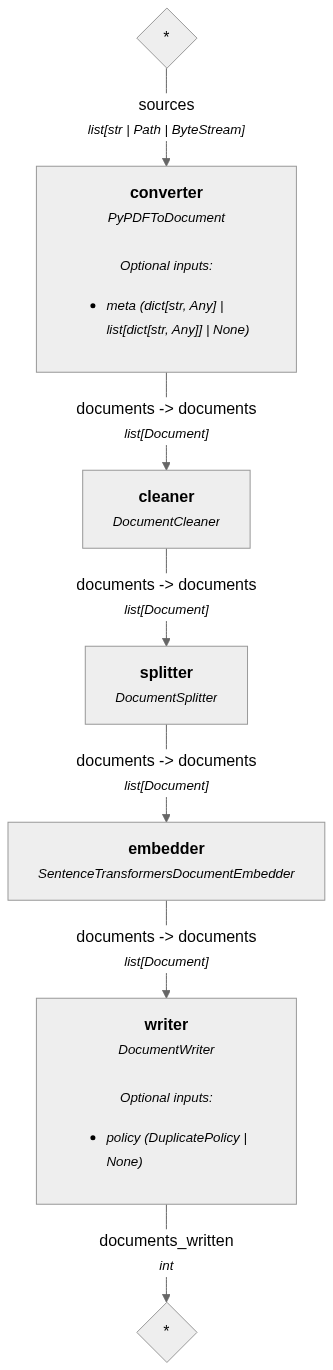

In [9]:
pipeline.show()

### Streamlit I/O

In [6]:
# InputLogic.py
# Remember the file uploader code and the ingestion function to ensure they are included in the final code.
# Use streamlit docs to ensure understanding of how to use the file uploader and how to handle the uploaded files correctly.

import tempfile
from pathlib import Path

import streamlit as st


def upload_pdfs():
    uploaded_files = st.file_uploader(
        "Upload PDF documents",
        type=["pdf"],
        accept_multiple_files=True,
        help="Upload files for summarization",
    )

    if not uploaded_files:
        return []

    temp_dir = Path(tempfile.mkdtemp(prefix="rag_uploads_"))
    saved_paths = []

    for upfile in uploaded_files:
        file_path = temp_dir / upfile.name
        with open(file_path, "wb") as f:
            f.write(upfile.getvalue())
        saved_paths.append(file_path)

    st.success(f"Saved {len(saved_paths)} file(s) to temporary storage")
    return saved_paths

### Ingestion

In [7]:
def ingestion(pipeline, sources):

    pipeline.warm_up()
    result = pipeline.run(data={"converter": {"sources": sources}})
    return result["writer"]["documents_written"]

### LLM Switch and Implementation

In [10]:
#Implement LLMs


from typing import Dict


KIMI_API_KEY = os.getenv("KIMI_API_KEY")
DEEPSEEK_API_KEY = os.getenv("DEEPSEEK_API_KEY")
MISTRAL_API_KEY = os.getenv("MISTRAL_API_KEY")


class LLMGateway:
    """
    Thin abstraction over the four LLM APIs.
    Each config points to an OpenAI-compatible endpoint.
    """

    CONFIGS = {
        "kimi": {
            "base_url": "https://openrouter.ai/api/v1",
            "model": "moonshotai/kimi-k2.6:free",
            "env_key": KIMI_API_KEY,
        },
        "deepseek": {
            "base_url": "https://openrouter.ai/api/v1",
            "model": "deepseek-v4-flash",
            "env_key": DEEPSEEK_API_KEY,
        },
        "mistral": {
            "base_url": "https://api.mistral.ai/v1",
            "model": "mistral-small-latest",
            "env_key": MISTRAL_API_KEY,
        },
# Connection Works; Payment Needed
        # "qwen": {
        #     "base_url": "https://openrouter.ai/api/v1",
        #     "model": "qwen/qwen3.6-flash",
        #     "env_key": "QWEN_API_KEY",
        # },
    }

    

In [11]:
# Generators

def __init__(self):
        self._clients: Dict[str, OpenAI] = {}

def _get_client(self, model_name: str) -> OpenAI:
        if model_name not in self._clients:
            cfg = self.CONFIGS[model_name]
            api_key = os.environ.get(cfg["env_key"])
            if not api_key:
                raise ValueError(
                    f"Missing API key: set {cfg['env_key']} in your environment."
                )
            self._clients[model_name] = OpenAI(
                api_key=api_key, base_url=cfg["base_url"]
            )
        return self._clients[model_name]

def generate(
        self, prompt: str, model_name: str, max_tokens: int = 2000, temperature: float = 0.3
    ) -> str:
        client = self._get_client(model_name)
        cfg = self.CONFIGS[model_name]

        response = client.chat.completions.create(
            model=cfg["model"],
            messages=[{"role": "user", "content": prompt}],
            max_tokens=max_tokens,
            temperature=temperature,
        )
        return response.choices[0].message.content

def get_context_window(self, model_name: str) -> int:
        windows = {
            "kimi": 2_000_000,
            "deepseek": 64_000,
            "mistral": 128_000,
            #"qwen": 32_000,
        }
        return windows.get(model_name, 32_000)


### Summarizer

In [ ]:
# Summarizer.py
#Fiction vs Nonfiction Logic stored here




def retrieve_comprehensive(document_store, genre="nonfiction", top_k=5):

    retriever = InMemoryEmbeddingRetriever(document_store=document_store)
    q_embedder = MistralTextEmbedder(
    api_key=Secret.from_env_var("MISTRAL_EMBED_API_KEY"),
    model="mistral-embed",
)

    
    q_embedder.warm_up()
    

    if genre == "fiction":
        sub_queries = [
            "main characters and conflict",
            "plot progression and climax",
            "themes and setting",
            "ending and resolution",
        ]
    else:
        sub_queries = [
            "introduction and problem statement",
            "methodology and approach",
            "key results and evidence",
            "conclusions and recommendations",
        ]

    all_docs = []
    seen_ids = set()

    for sq in sub_queries:
        embedding = q_embedder.run(text=sq)["embedding"]
        result = retriever.run(query_embedding=embedding, top_k=top_k)

        for doc in result["documents"]:
            if doc.id not in seen_ids:
                all_docs.append(doc)
                seen_ids.add(doc.id)

    # Restore original reading order
    all_docs.sort(key=lambda d: d.meta.get("page_number", 0))
    return all_docs


def _build_full_prompt(text, genre):
    if genre == "fiction":
        system = (
            "Provide a literary analysis alongisde a comprehensive summary "
            "cover the protagonist's arc, major conflicts, themes, and resolution. "
            "No bullet points."
        )
    else:
        system = (
            "Provide an executive summary covering "
            "the central thesis, methodology, key findings, and conclusions. "
            "Use structured analysis and provide bullet points as needed."
        )
    return f"{system}\n\n{text}\n\nProvide a summary of all file(s)."


def _build_map_prompt(chunk, genre):
    if genre == "fiction":
        return (
            "Summarize this passage from a fictional work. Focus on plot events, "
            f"character actions, and setting:\n\n{chunk}"
        )
    return (
        "Summarize this passage from a non-fiction document. Focus on key "
        f"arguments, evidence, and conclusions:\n\n{chunk}"
    )


def _build_reduce_prompt(summaries, genre):
    combined = "\n\n---\n\n".join(summaries)
    if genre == "fiction":
        system = (
            "Synthesize these section summaries into a cohesive narrative overview. "
            "Preserve chronological order, identify the protagonist's arc, major "
            "conflicts, and thematic resolution. Write flowing prose."
        )
    else:
        system = (
            "Synthesize these section summaries into an executive summary. Identify "
            "the central thesis, key evidence, methodology highlights, and actionable "
            "conclusions. Use structured paragraphs."
        )
    return f"{system}\n\nSource summaries:\n\n{combined}\n\nProduce a section summary."


def summarize(document_store, genre, model_name):

    # Orchestrates whole-document summarization.
    # Uses Direct Mode if content fits the model's context window;
    # Otherwise falls back to Map-Reduce.

    chunks = retrieve_comprehensive(document_store, genre=genre)

    if not chunks:
        return "No documents found. Please upload PDFs first."

    full_text = "\n\n".join([d.content for d in chunks])
    rough_tokens = len(full_text.split()) * 1.3
    context_window = get_context_window(model_name)

    # Direct Mode (70% buffer)
    if rough_tokens < (context_window * 0.7):
        prompt = _build_full_prompt(full_text, genre)
        return generate(prompt, model_name, max_tokens=3000)

    # Map-Reduce Mode
    chunk_summaries = []
    for chunk in chunks:
        mini_prompt = _build_map_prompt(chunk.content, genre)
        mini_summary = generate(mini_prompt, model_name, max_tokens=500)
        chunk_summaries.append(mini_summary)

    reduce_prompt = _build_reduce_prompt(chunk_summaries, genre,)
    return generate(reduce_prompt, model_name, max_tokens=3000)

### Streamlit

In [ ]:
#Streamlit.py


# Session State initialization

if "document_store" not in st.session_state:
    st.session_state.document_store = doc_store
if "engine_ready" not in st.session_state:
    st.session_state.engine_ready = False

st.set_page_config(page_title="HSRG PDF Summarizer", layout="wide")
st.title("HSRG PDF Summarizer")


# Sidebar

st.sidebar.header("Configuration")

model_name = st.sidebar.selectbox(
    "Select LLM",
    options=["Kimi", "Deepseek", "Mistral"],
    index=0,
)

genre = st.sidebar.radio(
    "Content Type",
    options=["Nonfiction", "Fiction"],
    index=0,
    help="Determines chunking strategy and prompt templates",
)


API_ENV_MAP = {
    "kimi": "KIMI_API_KEY",
    "deepseek": "DEEPSEEK_API_KEY",
    "mistral": "MISTRAL_API_KEY",
    #"qwen": "QWEN_API_KEY",
}


# Upload PDF

st.header("Upload Documents")
upload = upload_pdfs()


# Index (Haystack Pipeline)

st.header("Index Documents")
ingest_disabled = len(upload) == 0

if st.button("Run Haystack Ingestion Pipeline", disabled=ingest_disabled):
    with st.spinner("Reading your document..."):

      docs_written = ingestion(pipeline, sources=upload)
       

    st.success(f"Pipeline complete: {docs_written} chunks indexed.")
    st.session_state.engine_ready = True


# Summarize

st.header("Generate Summary")

if not st.session_state.engine_ready:
    st.info("Upload and ingest PDFs to enable summarization.")
else:
    if st.button("Summarize"):
        with st.spinner(f"Generating summary via {model_name}..."):
            summary = summarize(
                document_store=st.session_state.document_store,
                genre=genre,
                model_name=model_name,
            )

        st.markdown("### Summary")
        st.markdown(summary)

        # Transparency: show retrieved chunks
        with st.expander("Retrieved Chunks for Debugging)"):
            docs = retrieve_comprehensive(st.session_state.document_store, genre=genre)
            for i, doc in enumerate(docs, 1):
                page = doc.meta.get("page_number", "N/A")
                st.markdown(f"**Chunk {i}** — Page {page}")
                st.text(doc.content[:300] + "...")
                st.divider()

2026-06-02 10:54:50.908 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-06-02 10:54:50.912 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-06-02 10:54:50.914 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-06-02 10:54:50.915 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-06-02 10:54:50.915 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-06-02 10:54:50.916 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-06-02 10:54:50.917 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-06-02 10:54:50.918 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar